**ASSIGNMENT 03: : Designing Charts to Communicate Insights Clearly**

**NAME: MISTHI GUPTA**   
**ROLL NO: 2503203100074**

#DATASET AND SETUPS

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

gap = px.data.gapminder()

gap_2007 = gap[gap["year"] == 2007]


sns.set_theme(style="whitegrid")

print(gap.head())

       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


#TASK1: RANKED BAR CHART

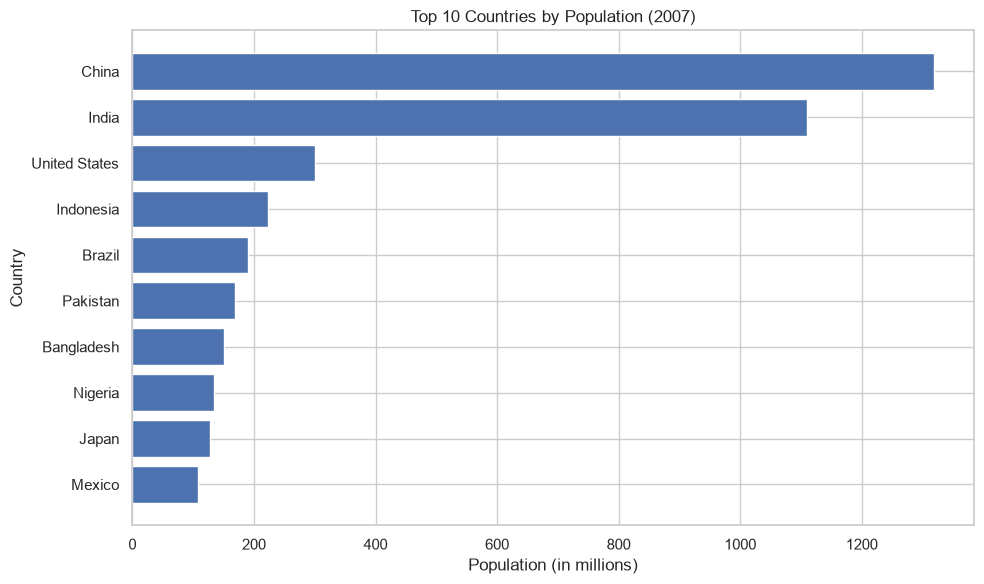

Answer: China and India are far ahead of the other countries.


In [22]:
top10 = gap_2007.nlargest(10, "pop")
top10 = top10.sort_values("pop")

plt.figure(figsize=(10, 6))
plt.barh(top10["country"], top10["pop"] / 1000000)

plt.title("Top 10 Countries by Population (2007)")
plt.xlabel("Population (in millions)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

print("Answer: China and India are far ahead of the other countries.")

#TASK2:LINE CHART

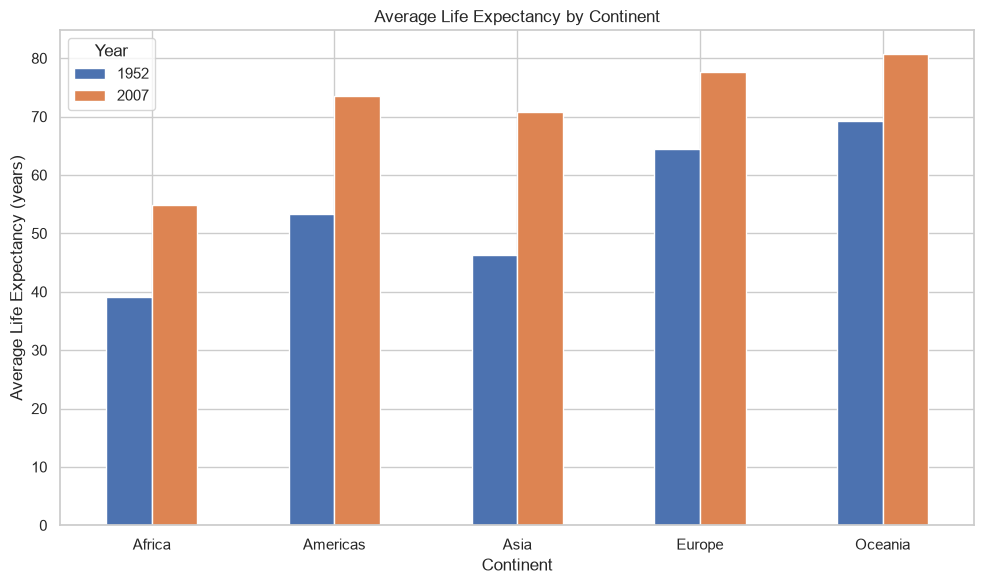

Most improved continent: Asia


In [23]:
g = gap[gap["year"].isin([1952, 2007])]
g = g.groupby(["continent", "year"])["lifeExp"].mean().unstack()

g.plot(kind="bar", figsize=(10, 6))

plt.title("Average Life Expectancy by Continent")
plt.xlabel("Continent")
plt.ylabel("Average Life Expectancy (years)")
plt.legend(title="Year")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

improvement = g[2007] - g[1952]
print("Most improved continent:", improvement.idxmax())

#TASK3:LINE CHART

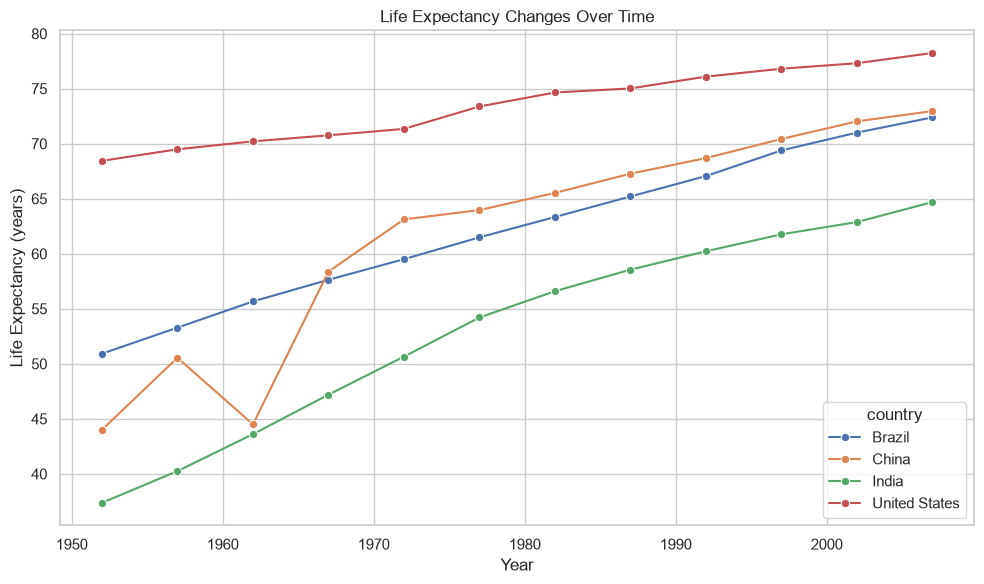

Lowest life expectancy in 1952: India
Fastest improvement: China
A line chart is suitable for showing changes over time.


In [24]:
countries = ["India", "China", "Brazil", "United States"]
data = gap[gap["country"].isin(countries)]

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=data,
    x="year",
    y="lifeExp",
    hue="country",
    marker="o"
)

plt.title("Life Expectancy Changes Over Time")
plt.xlabel("Year")
plt.ylabel("Life Expectancy (years)")

plt.tight_layout()
plt.show()

start = data[data["year"] == 1952]
lowest = start.loc[start["lifeExp"].idxmin(), "country"]

growth = data.groupby("country").apply(
    lambda x: x.loc[x["year"] == 2007, "lifeExp"].iloc[0]
    - x.loc[x["year"] == 1952, "lifeExp"].iloc[0],
    include_groups=False
)

print("Lowest life expectancy in 1952:", lowest)
print("Fastest improvement:", growth.idxmax())
print("A line chart is suitable for showing changes over time.")

#TASK4: LINEAR SCALE AND LOG SCALE

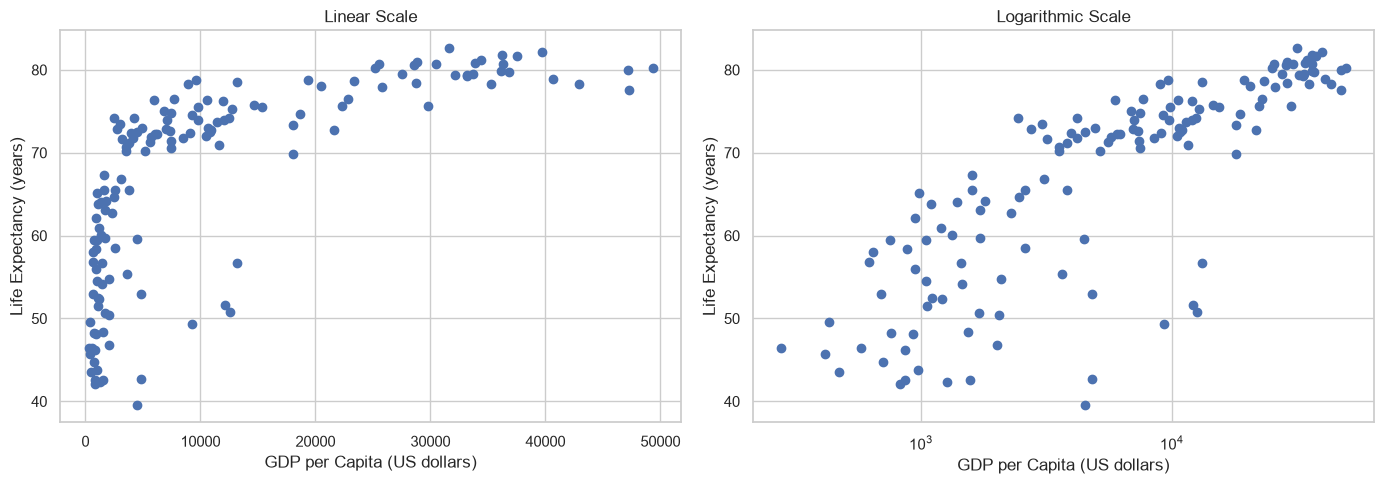

Answer: The log-scale chart makes the relationship easier
to see across countries with different income levels.


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Linear scale
ax[0].scatter(gap_2007["gdpPercap"], gap_2007["lifeExp"])
ax[0].set_title("Linear Scale")
ax[0].set_xlabel("GDP per Capita (US dollars)")
ax[0].set_ylabel("Life Expectancy (years)")

# Logarithmic scale
ax[1].scatter(gap_2007["gdpPercap"], gap_2007["lifeExp"])
ax[1].set_xscale("log")
ax[1].set_title("Logarithmic Scale")
ax[1].set_xlabel("GDP per Capita (US dollars)")
ax[1].set_ylabel("Life Expectancy (years)")

plt.tight_layout()
plt.show()

print("Answer: The log-scale chart makes the relationship easier")
print("to see across countries with different income levels.")

#TASK5: INTERACTIVE BUBBLE CHART

In [26]:

fig = px.scatter(
    gap_2007,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    color="continent",
    hover_name="country",
    log_x=True,
    size_max=50,
    title="GDP, Life Expectancy and Population (2007)",
    labels={
        "gdpPercap": "GDP per Capita (US dollars)",
        "lifeExp": "Life Expectancy (years)",
        "pop": "Population",
        "continent": "Continent"
    }
)

fig.show()

low_life = gap_2007[gap_2007["lifeExp"] < 60]

print("Continent with the most countries below 60 years:")
print(low_life["continent"].value_counts().idxmax())

print("Two largest population bubbles:")
print(gap_2007.nlargest(2, "pop")["country"].to_list())


Continent with the most countries below 60 years:
Africa
Two largest population bubbles:
['China', 'India']


#TASK6: CORRELATION HEATMAP

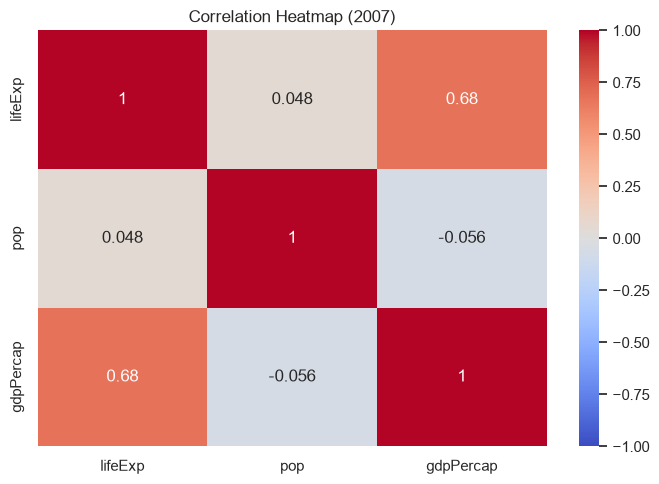

            lifeExp       pop  gdpPercap
lifeExp    1.000000  0.047553   0.678662
pop        0.047553  1.000000  -0.055676
gdpPercap  0.678662 -0.055676   1.000000


In [27]:
corr = gap_2007[["lifeExp", "pop", "gdpPercap"]].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap (2007)")
plt.tight_layout()
plt.show()

print(corr)

#TASK7: PATTERN HEATMAP

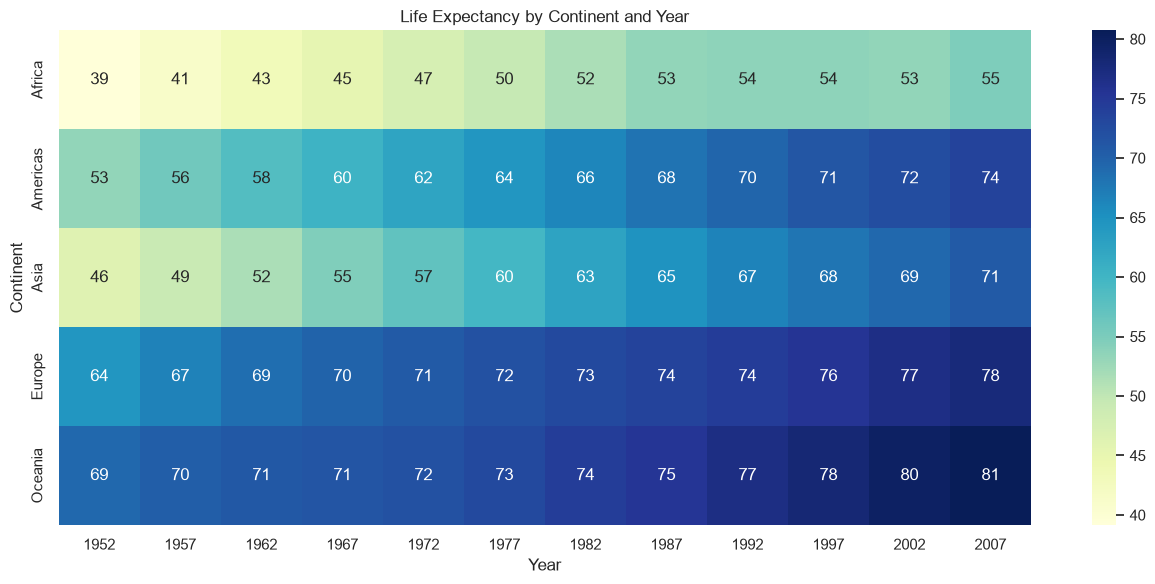

Answer: Africa generally has the lowest life expectancy.


In [28]:
pivot = gap.pivot_table(
    index="continent",
    columns="year",
    values="lifeExp",
    aggfunc="mean"
)

plt.figure(figsize=(13, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Life Expectancy by Continent and Year")
plt.xlabel("Year")
plt.ylabel("Continent")

plt.tight_layout()
plt.show()

print("Answer: Africa generally has the lowest life expectancy.")

#TASK8:CHOOSE A RIGHT CHART

In [29]:
situations = [
    ("Compare students in five branches",
     "Bar chart",
     "Compares categories."),

    ("Show monthly temperature changes",
     "Line chart",
     "Shows changes over time."),

    ("Study hours versus marks",
     "Scatter plot",
     "Shows the relationship between two variables."),

    ("Marks distribution of 100 students",
     "Histogram",
     "Shows the distribution of numerical data."),

    ("Attendance of five subjects over six weeks",
     "Heatmap",
     "Shows patterns across subjects and weeks.")
]

for situation, chart, reason in situations:
    print("\nSituation:", situation)
    print("Best chart:", chart)
    print("Reason:", reason)


Situation: Compare students in five branches
Best chart: Bar chart
Reason: Compares categories.

Situation: Show monthly temperature changes
Best chart: Line chart
Reason: Shows changes over time.

Situation: Study hours versus marks
Best chart: Scatter plot
Reason: Shows the relationship between two variables.

Situation: Marks distribution of 100 students
Best chart: Histogram
Reason: Shows the distribution of numerical data.

Situation: Attendance of five subjects over six weeks
Best chart: Heatmap
Reason: Shows patterns across subjects and weeks.


#TASK9: FIX A POOR CHART

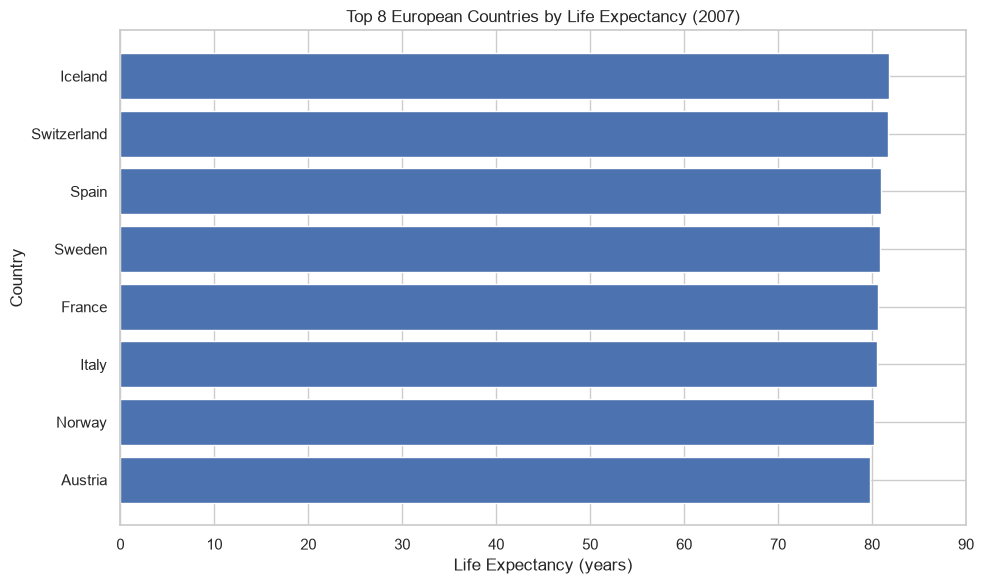

Problems in the original chart:
1. Too many different colours.
2. The y-axis starts at 79 instead of zero.
3. Country names may be difficult to read.
4. The title is missing.
5. Axis labels are missing.
After correction, the chart is clearer and differences
between countries are not exaggerated by a truncated axis.


In [30]:
bad = gap_2007[gap_2007["continent"] == "Europe"].nlargest(
    8, "lifeExp"
)

bad = bad.sort_values("lifeExp")

plt.figure(figsize=(10, 6))

plt.barh(bad["country"], bad["lifeExp"])

plt.title("Top 8 European Countries by Life Expectancy (2007)")
plt.xlabel("Life Expectancy (years)")
plt.ylabel("Country")
plt.xlim(0, 90)

plt.tight_layout()
plt.show()

print("Problems in the original chart:")
print("1. Too many different colours.")
print("2. The y-axis starts at 79 instead of zero.")
print("3. Country names may be difficult to read.")
print("4. The title is missing.")
print("5. Axis labels are missing.")

print("After correction, the chart is clearer and differences")
print("between countries are not exaggerated by a truncated axis.")